# 04 · Final evaluation on the test set

This is the **first and only time** we use the test set. Its 45,895 people were set aside in notebook 02 and
haven't influenced any choice so far, so the scores here are an honest estimate of how the models would do
on new people.

We will:
1. Score both saved models on the test set
2. Compare them with confusion matrices, ROC curves and precision-recall curves
3. Explore how the **decision threshold** changes precision and recall
4. Look at which features each model relies on
5. Choose the better model

## 1. Load the models and the test set

In [1]:
import sys
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.metrics import classification_report

PROJECT_DIR = Path.cwd().parent
sys.path.append(str(PROJECT_DIR))

from src.evaluate import (BLUE, GREY, metrics_table, plot_confusion_matrices, plot_precision_recall_curves,
                          plot_roc_curves, plot_top_features, predict_with_threshold, threshold_table)

PROCESSED_DIR = PROJECT_DIR / "data" / "processed"
MODELS_DIR = PROJECT_DIR / "models"
FIGURES_DIR = PROJECT_DIR / "reports" / "figures"

plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "font.size": 11})


def save_chart(fig, filename):
    """Save a chart to reports/figures/ at a good resolution."""
    fig.savefig(FIGURES_DIR / filename, dpi=150, bbox_inches="tight")
    print(f"Saved reports/figures/{filename}")


# The two trained pipelines from notebook 03 (each includes its fitted scaler)
models = {
    "Logistic Regression": joblib.load(MODELS_DIR / "logistic_regression.joblib"),
    "Random Forest (tuned)": joblib.load(MODELS_DIR / "random_forest.joblib"),
}

# The test set: used here for the first time
X_test = pd.read_csv(PROCESSED_DIR / "X_test.csv")
y_test = pd.read_csv(PROCESSED_DIR / "y_test.csv").squeeze()

print(f"Test set: {len(X_test):,} people, of whom {y_test.sum():,} ({y_test.mean():.1%}) have diabetes")

Test set: 45,895 people, of whom 7,019 (15.3%) have diabetes


## 2. Scores on the test set

In [2]:
for name, model in models.items():
    print(f"===== {name} =====")
    print(classification_report(y_test, model.predict(X_test),
                                target_names=["No diabetes", "Diabetes"], digits=3))

===== Logistic Regression =====
              precision    recall  f1-score   support

 No diabetes      0.942     0.706     0.807     38876
    Diabetes      0.318     0.760     0.449      7019

    accuracy                          0.714     45895
   macro avg      0.630     0.733     0.628     45895
weighted avg      0.847     0.714     0.752     45895

===== Random Forest (tuned) =====


              precision    recall  f1-score   support

 No diabetes      0.942     0.723     0.818     38876
    Diabetes      0.329     0.753     0.458      7019

    accuracy                          0.728     45895
   macro avg      0.635     0.738     0.638     45895
weighted avg      0.848     0.728     0.763     45895



**How to read a classification report:** each row is one class.
- The **"Diabetes" row** matters most for us: its *recall* is the share of diabetic people the model found.
- **support** is the number of people in that class.
- **accuracy** sits near 0.7, which is *below* the 85% a model that always says "no diabetes" would get.
  That is expected and fine: our models deliberately trade some accuracy to find far more diabetes cases (see notebook 01).

In [3]:
test_scores = metrics_table(models, X_test, y_test)
test_scores.round(3)

,precision,recall,f1,roc_auc,accuracy
Logistic Regression,0.318,0.760,0.449,0.811,0.714
Random Forest (tuned),0.329,0.753,0.458,0.817,0.728


In [4]:
# Compare with the cross-validation scores from notebook 03 (same models, training data)
cv_scores = pd.read_csv(PROJECT_DIR / "reports" / "model_comparison.csv").set_index("model")
pd.DataFrame({
    "CV ROC-AUC (train)": cv_scores.loc[["Logistic Regression", "Random Forest (tuned)"], "roc_auc_mean"],
    "Test ROC-AUC": test_scores["roc_auc"],
}).round(3)

,CV ROC-AUC (train),Test ROC-AUC
Logistic Regression,0.807,0.811
Random Forest (tuned),0.812,0.817


**The test scores closely match the cross-validation scores** (ROC-AUC 0.811 vs 0.807 for Logistic Regression,
0.817 vs 0.812 for the Random Forest). The models didn't overfit, and cross-validation gave a reliable
picture before we touched the test set.

## 3. Confusion matrices

Saved reports/figures/confusion_matrices.png


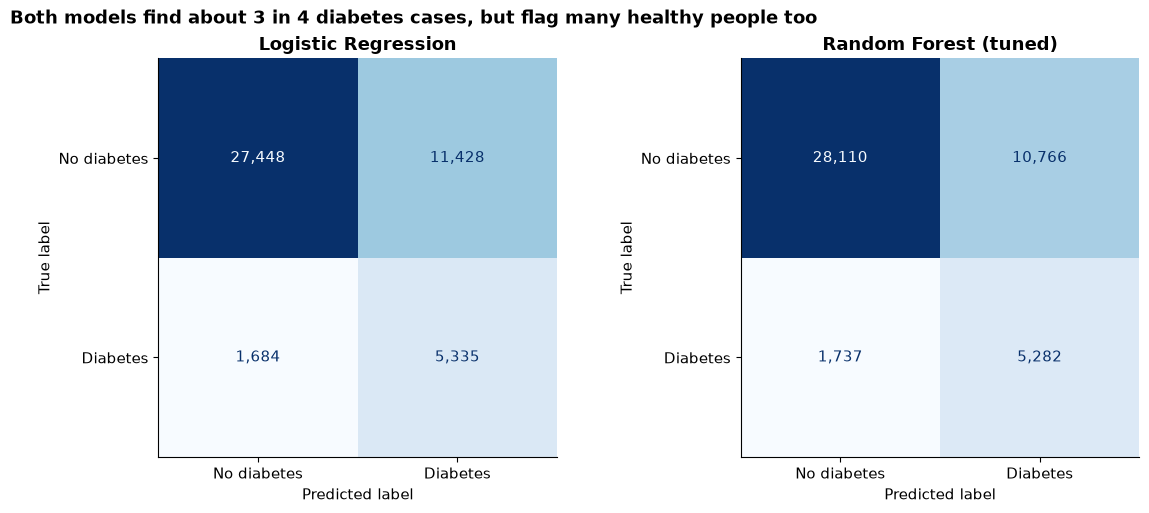

In [5]:
fig = plot_confusion_matrices(models, X_test, y_test)
fig.suptitle("Both models find about 3 in 4 diabetes cases, but flag many healthy people too",
             x=0.01, ha="left", fontweight="bold", y=1.02)
save_chart(fig, "confusion_matrices.png")
plt.show()

**How to read it:** rows are the truth, columns are the prediction.
- **Bottom right (true positives):** diabetic people correctly flagged.
- **Bottom left (false negatives):** diabetic people the model **missed**. These are the costly mistakes in screening.
- **Top right (false positives):** healthy people wrongly flagged. They would get an unnecessary follow-up test.
- **Top left (true negatives):** healthy people correctly cleared.

At the default threshold of 0.5, the Random Forest finds **5,282** of the 7,019 diabetes cases and misses **1,737**.
It also wrongly flags **10,766** healthy people. Logistic Regression is very similar (5,335 found, 1,684 missed,
11,428 false alarms).

## 4. ROC and precision-recall curves

Saved reports/figures/roc_and_precision_recall_curves.png


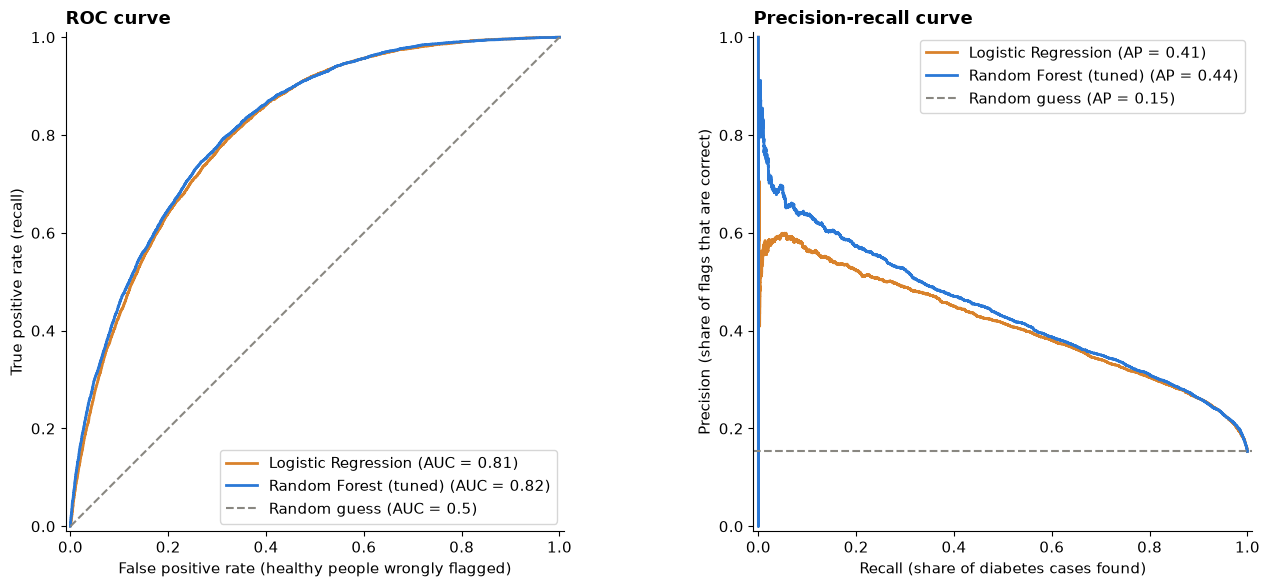

In [6]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))
plot_roc_curves(models, X_test, y_test, ax1)
plot_precision_recall_curves(models, X_test, y_test, ax2)
fig.tight_layout()
save_chart(fig, "roc_and_precision_recall_curves.png")
plt.show()

**ROC curve (left):** each point is one possible threshold. The curve shows how many diabetes cases are found
(up) against how many healthy people are wrongly flagged (right). Further towards the top-left corner is better.
Both models are well above the random-guess line and almost on top of each other. The Random Forest is very
slightly higher everywhere (**AUC 0.817** vs 0.811).

**Precision-recall curve (right):** this view focuses on the diabetes class, so it is more informative when one
class is rare. Moving right finds more cases, but the share of correct alerts falls. Random guessing would give a
precision of only 0.15 (the diabetes rate). The models reach an **average precision (AP)** of **0.44**
(Random Forest) and **0.41** (Logistic Regression): about 3 times better than random, but far from perfect.

## 5. Threshold analysis

A model outputs a **probability** of diabetes for each person. The **threshold** is the cut-off for calling
someone "diabetic". The default is 0.5, but we can move it:
- **Lower threshold:** more people flagged, so more cases found (higher recall) but more false alarms (lower precision).
- **Higher threshold:** fewer people flagged, so fewer false alarms but more missed cases.

We analyse the **better model** by test ROC-AUC.

In [7]:
best_name = test_scores["roc_auc"].idxmax()
best_model = models[best_name]
print(f"Better model by test ROC-AUC: {best_name}")

thresholds = threshold_table(best_model, X_test, y_test)
thresholds.style.format({"precision": "{:.1%}", "recall": "{:.1%}", "f1": "{:.3f}",
                         "people_flagged": "{:,}", "diabetes_cases_missed": "{:,}"}).hide(axis="index")

Better model by test ROC-AUC: Random Forest (tuned)


threshold,precision,recall,f1,people_flagged,diabetes_cases_missed
0.300000,24.8%,92.3%,0.391,"26,129",541
0.400000,28.5%,85.7%,0.428,"21,094","1,007"
0.500000,32.9%,75.3%,0.458,"16,048","1,737"
0.600000,38.3%,61.0%,0.471,"11,190","2,735"


Saved reports/figures/threshold_precision_recall.png


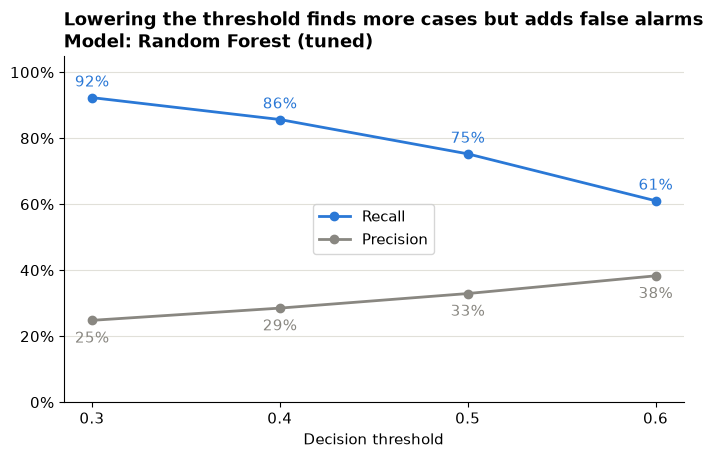

In [8]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(thresholds["threshold"], thresholds["recall"], marker="o", color=BLUE, linewidth=2, label="Recall")
ax.plot(thresholds["threshold"], thresholds["precision"], marker="o", color=GREY, linewidth=2, label="Precision")

# Label every point with its value
for _, row in thresholds.iterrows():
    ax.annotate(f"{row['recall']:.0%}", (row["threshold"], row["recall"]), textcoords="offset points",
                xytext=(0, 8), ha="center", color=BLUE)
    ax.annotate(f"{row['precision']:.0%}", (row["threshold"], row["precision"]), textcoords="offset points",
                xytext=(0, -16), ha="center", color=GREY)

ax.set_xticks(thresholds["threshold"])
ax.set_ylim(0, 1.05)
ax.yaxis.set_major_formatter(lambda v, pos: f"{v:.0%}")
ax.set_xlabel("Decision threshold")
ax.set_title(f"Lowering the threshold finds more cases but adds false alarms\nModel: {best_name}",
             loc="left", fontweight="bold")
ax.legend(loc="center")
ax.grid(axis="y", color="#e1e0d9")
save_chart(fig, "threshold_precision_recall.png")
plt.show()

### The trade-off for a screening use case

Imagine the model is used to **screen** people and decide who should get a diabetes blood test.

- **Missing a diabetic person is costly.** They go undiagnosed, and untreated diabetes can lead to serious
  complications.
- **A false alarm is cheap by comparison.** The person takes a routine blood test, which comes back normal.

So in screening, **recall matters more than precision**, and a threshold **below 0.5** makes sense.
With the Random Forest on the test set:

| Threshold | Diabetes cases found | Cases missed | Share of flags that are correct |
|---|---|---|---|
| 0.5 (default) | 75.3% | 1,737 | 32.9% |
| 0.4 | 85.7% | 1,007 | 28.5% |
| **0.3** | **92.3%** | **541** | 24.8% |

Moving from 0.5 to **0.3** cuts the missed cases by more than two-thirds (1,737 to 541). The price is about
10,000 more people flagged for testing (16,048 to 26,129 of 45,895), and only about 1 in 4 flags is a real case.
A threshold of 0.3–0.4 fits a screening tool. The exact choice depends on how many follow-up tests the health
service can afford.

**Note:** in a real project the threshold should be chosen on the training data (with cross-validation), not
on the test set. Here we only *show* the trade-off on the test set; we don't tune the model on it.

## 6. Which features do the models rely on?

Saved reports/figures/feature_importance.png


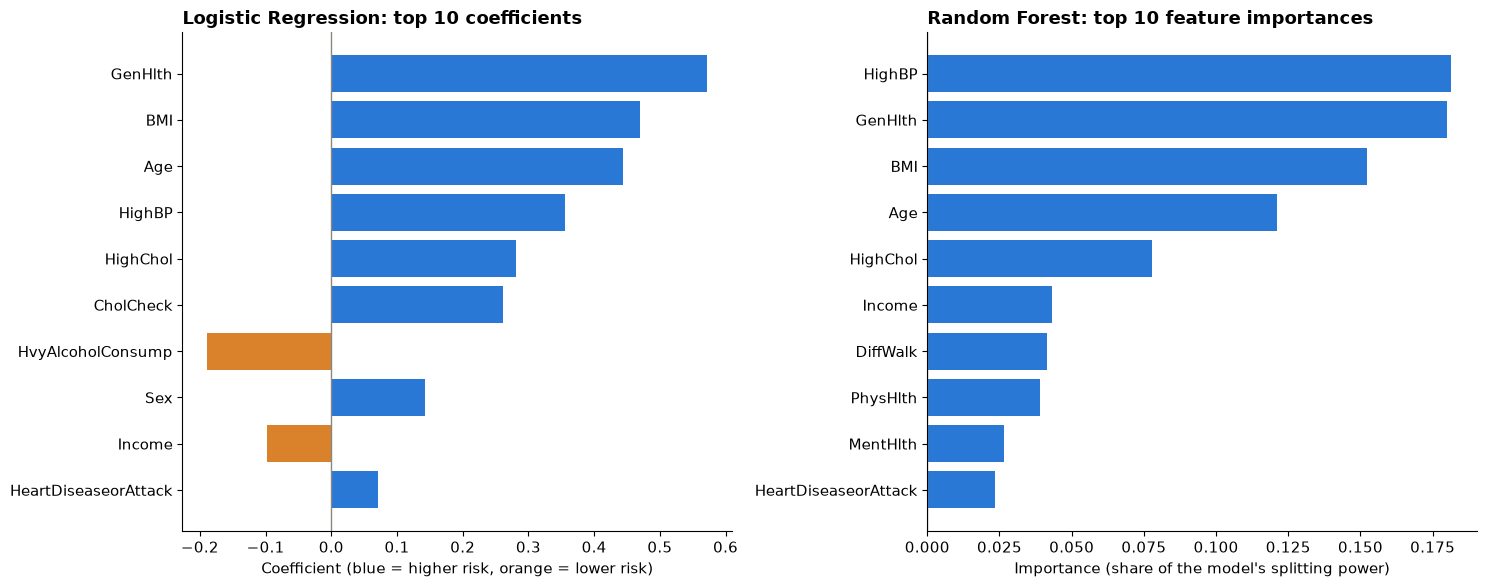

In [9]:
log_reg_model = models["Logistic Regression"].named_steps["model"]
forest_model = models["Random Forest (tuned)"].named_steps["model"]

coefficients = pd.Series(log_reg_model.coef_[0], index=X_test.columns)
importances = pd.Series(forest_model.feature_importances_, index=X_test.columns)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))
plot_top_features(coefficients, "Logistic Regression: top 10 coefficients",
                  "Coefficient (blue = higher risk, orange = lower risk)", ax1)
plot_top_features(importances, "Random Forest: top 10 feature importances",
                  "Importance (share of the model's splitting power)", ax2)
fig.tight_layout()
save_chart(fig, "feature_importance.png")
plt.show()

**How to read the two charts:**
- **Logistic Regression coefficients:** because the features were scaled in the pipeline, the coefficients are
  comparable. Each one shows how much the predicted risk changes when that feature goes up by one standard
  deviation, with everything else held the same. Positive (blue) means higher predicted risk, negative (orange) lower.
- **Random Forest importances:** how much each feature helped the trees separate diabetic from non-diabetic people.
  They are always positive, so they show *how much* a feature is used, not in which direction. This kind of
  importance can favour features with many different values (like BMI), so treat it as a rough ranking.

**What they show:**
- **Both models rely on the same four features most:** general health, BMI, age and high blood pressure, followed
  by high cholesterol. This matches the EDA, where these had the strongest patterns.
- `CholCheck` has a fairly large positive coefficient (0.26). People with diabetes are usually monitored more,
  so they are more likely to have had a cholesterol check. This is probably a **result** of having diabetes, not a risk factor.
- `HvyAlcoholConsump` has a negative coefficient (−0.19). This is a pattern in the survey answers, not evidence
  that drinking protects against diabetes.

These are **associations the models learned**, not causes.

## 7. Conclusion: which model is better?

**The tuned Random Forest is slightly better on every test score**, but the margin is small:

| Test score (threshold 0.5) | Logistic Regression | Random Forest (tuned) |
|---|---|---|
| ROC-AUC | 0.811 | **0.817** |
| Average precision | 0.41 | **0.44** |
| F1 | 0.449 | **0.458** |
| Precision | 0.318 | **0.329** |
| Recall | **0.760** | 0.753 |

- **Why the Random Forest wins:** it ranks people by risk slightly better (ROC-AUC +0.006, average precision +0.03),
  and it can capture non-straight-line patterns, such as the diabetes rate levelling off after age 75, which
  Logistic Regression can't.
- **Why Logistic Regression is still a strong choice:** it is within 0.006 ROC-AUC, trains in seconds, is a tiny
  file (vs 41 MB), and its coefficients are easy to explain to doctors.
- **For a screening tool**, I would use the **Random Forest with a threshold of about 0.3**. It finds **92%**
  of diabetes cases, and the extra false alarms only lead to a cheap follow-up test. If explaining each prediction
  matters more than a small gain in accuracy, Logistic Regression is a very close second.

**Limitations:** the data comes from a 2015 US phone survey, with self-reported answers. "Diabetes" also includes
prediabetes. And some features (like general health or `CholCheck`) may be partly a *result* of a diabetes
diagnosis rather than a warning sign.